# Chapter 16: Self-hosting open models

Companion notebook for [ch16/README.md](../README.md).

The GPU benchmarks need the whole card, so they don't run inside this notebook.
[`run_gpu_benchmarks.sh`](run_gpu_benchmarks.sh) starts each engine, runs
[`ch16_bench.py`](ch16_bench.py) against it, and writes `results/<label>.json` plus server logs
in `results/logs/`. **This notebook reads those result files** (their run dates are printed
below), turns them into tables and charts, and does the capacity and cost math. The hosted
baseline (`openrouter-gpt-6-luna`) came from the same `ch16_bench.py`, pointed at OpenRouter.

In [1]:
import json
import re
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd()))
from ch16_bench import plot
from ch16_capacity import (ModelShape, breakeven_tokens_per_s, kv_bytes_per_token,
                           max_cached_tokens, usd_per_million_tokens)

RESULTS, IMAGES = Path("results"), Path("../images")
runs = {p.stem: json.loads(p.read_text()) for p in sorted(RESULTS.glob("*.json"))}
startup = {r["label"]: r for r in map(json.loads, (RESULTS / "startup.jsonl").read_text().splitlines())}
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                      "--format=csv,noheader"], capture_output=True, text=True).stdout.strip())
for label, r in runs.items():
    print(f"{label:<24} run {r['date']}  model={r['model']}")

NVIDIA GeForce RTX 3090, 24576 MiB, 595.99.02
llamacpp-bf16            run 2026-11-09T06:09:56+00:00  model=qwen3-8b
llamacpp-q4-kvu          run 2026-11-09T06:37:11+00:00  model=qwen3-8b
llamacpp-q4              run 2026-11-09T06:03:00+00:00  model=qwen3-8b
ollama-default           run 2026-11-09T05:55:38+00:00  model=qwen3:8b
ollama-np32              run 2026-11-09T05:59:24+00:00  model=qwen3:8b
openrouter-gpt-6-luna    run 2026-11-07T13:38:05+00:00  model=openai/gpt-6-luna
sglang-bf16-mem080       run 2026-11-09T06:25:34+00:00  model=Qwen/Qwen3-8B
sglang-bf16              run 2026-11-09T06:33:34+00:00  model=Qwen/Qwen3-8B
vllm-bf16                run 2026-11-09T06:17:16+00:00  model=Qwen/Qwen3-8B


## The data: benchmark prompts from the ShopFlow docs

Each request gets a unique ticket number plus a different 512-token window of the 36 ShopFlow
docs, then the same instruction. Nothing is shared beyond the first couple of tokens, so prefix
caching can't help.

In [2]:
import tiktoken
from ch16_bench import build_prompts, load_corpus

enc = tiktoken.get_encoding("o200k_base")
corpus = load_corpus()
print(f"{len(corpus.split()):,} words, {len(enc.encode(corpus)):,} o200k tokens in the corpus")
p = build_prompts(2, 512, corpus, enc, seed=16)[1]
print(len(enc.encode(p)), "tokens in this prompt\n")
print(p[:420], "\n...\n", p[-300:])

22,822 words, 31,225 o200k tokens in the corpus
512 tokens in this prompt

Ticket 00001-7b00c7f4. Documents:

. Security & Data Platform reviews it. Approved access is time-limited.
3. Access is logged and reviewed quarterly.

Exceptions to the `shopflow_ro` email restriction are not granted for AI tools.

## Reporting a Suspected Exposure

If you posted PII in the wrong place or suspect a data leak:

1. Delete the message if you can, and note where it was posted.
2. Notify Security & Data  
...
 tems, or items missing original packaging, marked as unused.
- Repeated "delivered but missing"

You are a ShopFlow support analyst. Using only the documents above, write a detailed briefing for a new support agent: summarize every rule, number and exception, with examples. Write at least 400 words.


## Concepts: how much KV cache fits?

The KV cache size per token follows from the model's `config.json`. We compare the napkin math
with what vLLM and SGLang reported at startup (from their logs).

In [3]:
cfg = next(Path.home().glob(".cache/huggingface/hub/models--Qwen--Qwen3-8B/snapshots/*/config.json"))
shape = ModelShape.from_config(cfg)
per_tok = kv_bytes_per_token(shape)
print(shape, f"-> {per_tok:,} bytes/token = {per_tok / 1024:.0f} KiB")
req = 512 + 256
print(f"one 768-token request: {req * per_tok / 2**20:.0f} MiB; 32 of them: {32 * req * per_tok / 2**30:.2f} GiB")

vllm_log = (RESULTS / "logs/vllm-bf16.server.log").read_text()
for pat in [r"Model loading took [^\n]*", r"Available KV cache memory: [^\n]*",
            r"GPU KV cache size: [^\n]*"]:
    print("vLLM log:", re.search(pat, vllm_log).group(0))
kv_gib = float(re.search(r"Available KV cache memory: ([\d.]+) GiB", vllm_log).group(1))
print(f"our math for {kv_gib} GiB: {max_cached_tokens(kv_gib * 2**30, shape):,} tokens")
for label in ["sglang-bf16-mem080", "sglang-bf16"]:
    log = (RESULTS / f"logs/{label}.server.log").read_text()
    print(f"{label}:", re.search(r"KV Cache is allocated\.[^\n]*", log).group(0))

ModelShape(num_layers=36, num_kv_heads=8, head_dim=128) -> 147,456 bytes/token = 144 KiB
one 768-token request: 108 MiB; 32 of them: 3.38 GiB
vLLM log: Model loading took 15.27 GiB memory and 10.616572 seconds
vLLM log: Available KV cache memory: 3.55 GiB
vLLM log: GPU KV cache size: 25,840 tokens, Maximum concurrency for 8,192 tokens per request: 3.15x
our math for 3.55 GiB: 25,850 tokens
sglang-bf16-mem080: KV Cache is allocated. dtype: torch.bfloat16, #tokens: 10845, K size: 0.74 GB, V size: 0.74 GB
sglang-bf16: KV Cache is allocated. dtype: torch.bfloat16, #tokens: 20013, K size: 1.37 GB, V size: 1.37 GB


## The benchmark tables (closed loop, 32 requests per level, 512-token prompts, 256 output tokens)

In [4]:
def table(label: str) -> pd.DataFrame:
    rows = []
    for lv in runs[label]["levels"]:
        rows.append({
            "c": lv["concurrency"], "ok": f"{lv['ok']}/{lv['requests']}",
            "TTFT p50 ms": lv["ttft_p50"] * 1000, "TTFT p95 ms": lv["ttft_p95"] * 1000,
            "TPOT p50 ms": lv["tpot_p50"] * 1000, "TPOT p95 ms": lv["tpot_p95"] * 1000,
            "E2E p95 s": lv["e2e_p95"], "out tok/s": lv["output_tok_per_s"],
            "avg out tok": lv["mean_completion_tokens"], "avg prompt tok": lv["mean_prompt_tokens"],
        })
    return pd.DataFrame(rows).set_index("c").round(1)

ENGINES = ["ollama-default", "ollama-np32", "llamacpp-q4", "llamacpp-q4-kvu", "llamacpp-bf16",
           "vllm-bf16", "sglang-bf16-mem080", "sglang-bf16", "openrouter-gpt-6-luna"]
for label in ENGINES:
    print(f"\n=== {label}")
    print(table(label).to_string())


=== ollama-default
       ok  TTFT p50 ms  TTFT p95 ms  TPOT p50 ms  TPOT p95 ms  E2E p95 s  out tok/s  avg out tok  avg prompt tok
c                                                                                                               
1   32/32        152.7        177.0          7.8          8.5        2.3      116.5        256.0           550.8
2   32/32       2305.1       2505.9          7.9          8.4        4.7      117.0        256.0           551.4
4   32/32       6640.3       6671.9          7.9          7.9        8.7      118.4        256.0           549.2
8   32/32      15292.4      15310.6          7.9          7.9       17.3      118.3        256.0           548.1
16  32/32      32566.9      32632.8          7.9          7.9       34.6      118.3        256.0           550.0
32  32/32      33706.6      63857.3          7.9          7.9       65.9      118.3        256.0           548.7

=== ollama-np32
       ok  TTFT p50 ms  TTFT p95 ms  TPOT p50 ms  TPOT p95 

## Which configurations meet the chapter's targets?

TTFT p95 < 2 s and TPOT p50 < 50 ms. We report the highest concurrency level that met both.

In [5]:
rows = []
for label in ENGINES:
    ok = [lv for lv in runs[label]["levels"]
          if lv["ok"] == lv["requests"] and lv["ttft_p95"] < 2.0 and lv["tpot_p50"] < 0.050]
    best = max(ok, key=lambda lv: lv["concurrency"]) if ok else None
    top = runs[label]["levels"][-1]
    rows.append({"engine": label,
                 "max c within targets": best["concurrency"] if best else 0,
                 "out tok/s there": round(best["output_tok_per_s"]) if best else 0,
                 "out tok/s at c=32": round(top["output_tok_per_s"]),
                 "TTFT p95 at c=32 (s)": round(top["ttft_p95"], 2)})
print(pd.DataFrame(rows).to_string(index=False))

               engine  max c within targets  out tok/s there  out tok/s at c=32  TTFT p95 at c=32 (s)
       ollama-default                     1              117                118                 63.86
          ollama-np32                     8              293                634                  4.98
          llamacpp-q4                     8              306                667                  4.50
      llamacpp-q4-kvu                     8              334                670                  4.60
        llamacpp-bf16                     8              196                464                  6.12
            vllm-bf16                     8              308                738                  3.97
   sglang-bf16-mem080                     8              317                385                 15.86
          sglang-bf16                     8              317                512                 10.57
openrouter-gpt-6-luna                    32             2292               2292   

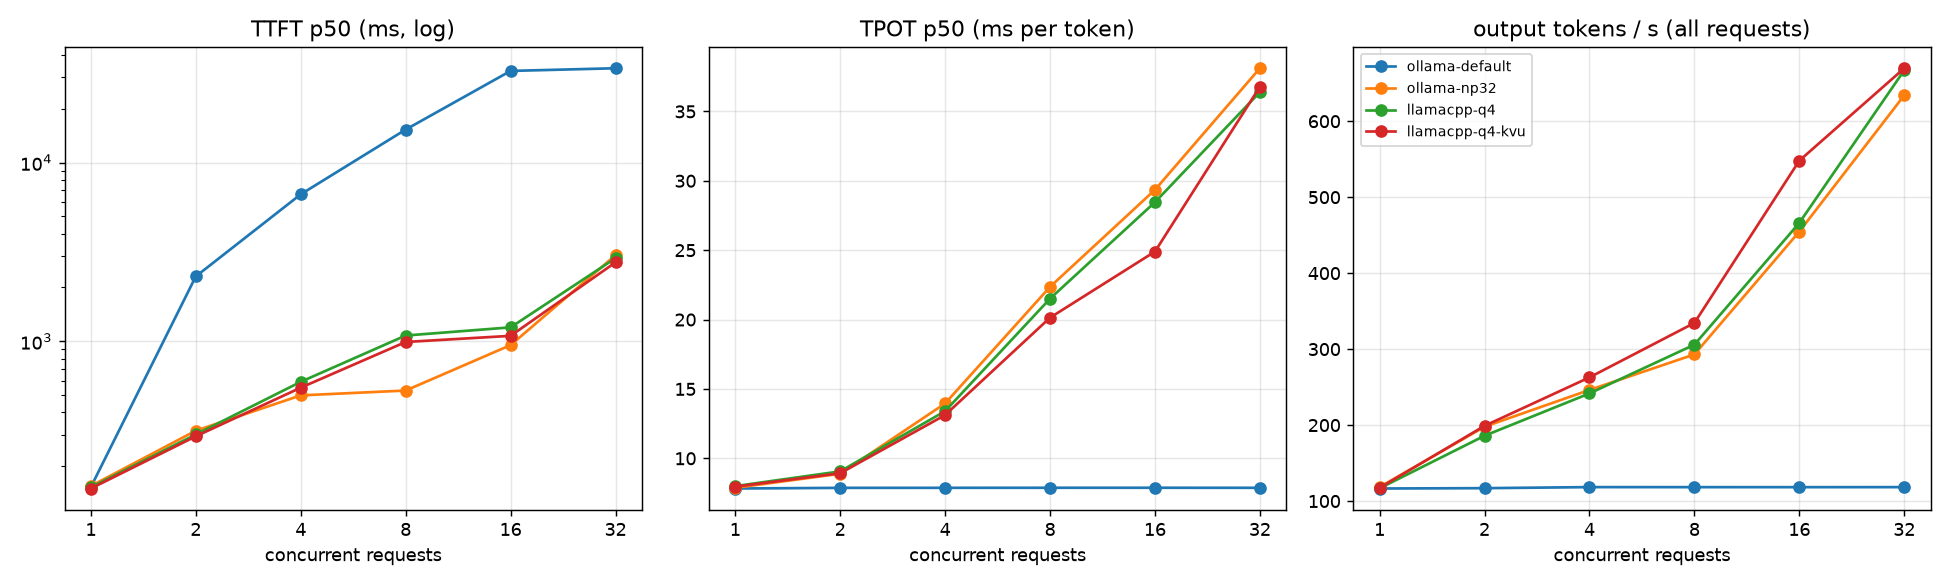

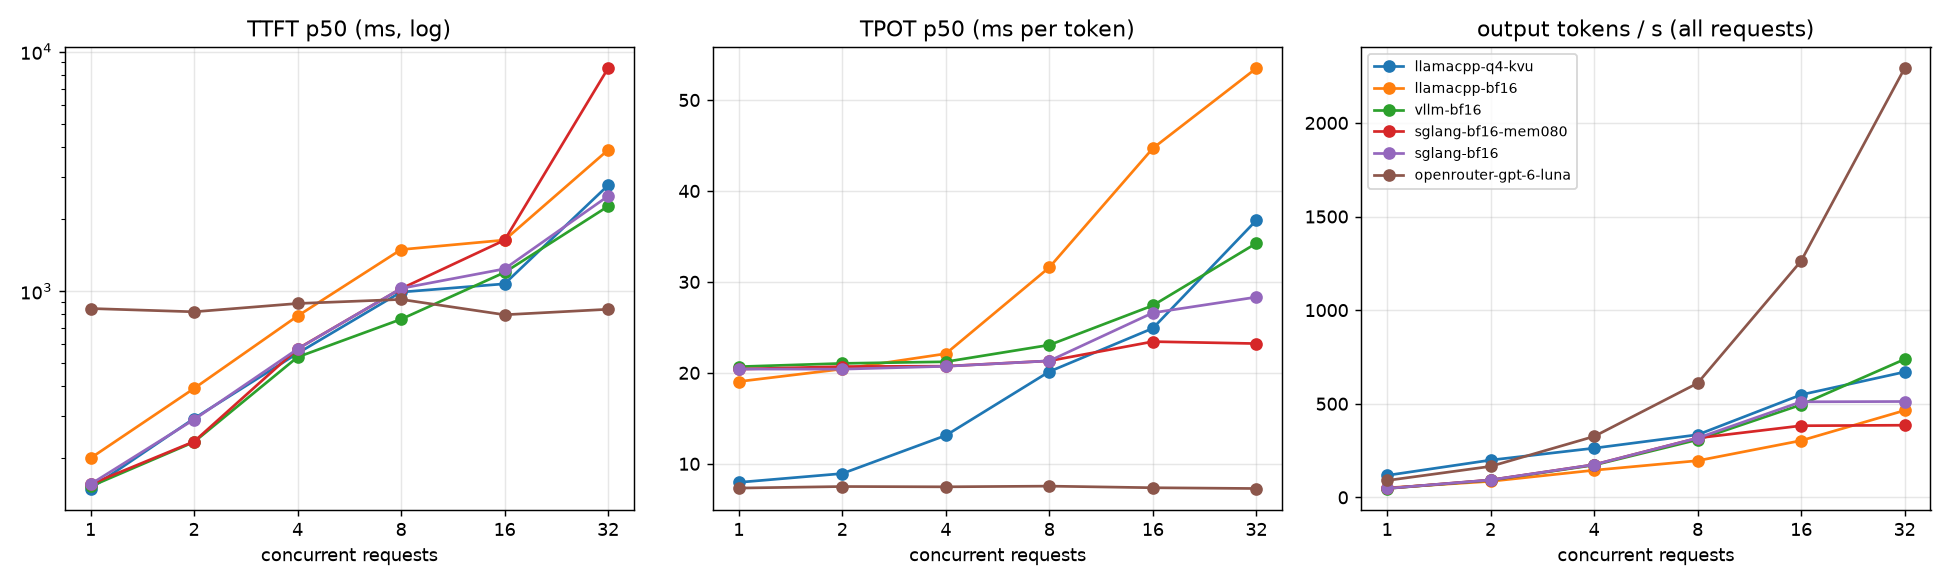

In [6]:
plot([runs[k] for k in ["ollama-default", "ollama-np32", "llamacpp-q4", "llamacpp-q4-kvu"]],
     IMAGES / "16-ollama-vs-llamacpp.png")
plot([runs[k] for k in ["llamacpp-q4-kvu", "llamacpp-bf16", "vllm-bf16", "sglang-bf16-mem080",
                        "sglang-bf16", "openrouter-gpt-6-luna"]], IMAGES / "16-engines.png")
display(Image(IMAGES / "16-ollama-vs-llamacpp.png"))
display(Image(IMAGES / "16-engines.png"))

## Where requests wait: TTFT of each request at concurrency 32

Sorted TTFTs of the 32 requests. A queue shows up as a staircase: the first requests start at
once, the rest wait for a free slot (or free KV-cache memory).

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label in ["ollama-default", "llamacpp-q4-kvu", "vllm-bf16", "sglang-bf16-mem080", "sglang-bf16",
              "openrouter-gpt-6-luna"]:
    lv = runs[label]["levels"][-1]
    ttfts = sorted(r["ttft"] for r in lv["raw"] if r["ok"])
    ax.plot(range(1, len(ttfts) + 1), ttfts, marker=".", label=label)
ax.set_yscale("log"); ax.set_xlabel("request (sorted by TTFT)"); ax.set_ylabel("TTFT (s, log)")
ax.set_title("TTFT of each of the 32 requests at concurrency 32"); ax.grid(alpha=0.3)
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(IMAGES / "16-ttft-staircase.png", dpi=130)
plt.show()

## Prefill: TTFT against prompt length (one request at a time)

Every prompt is new, so TTFT includes reading the whole prompt. `prompt tokens (server)` is what
the server says it processed; compare it with the target.

In [8]:
rows = []
for p in sorted((RESULTS / "prefill").glob("*.json")):
    d = json.loads(p.read_text())
    lv = d["levels"][0]
    rows.append({"engine": d["label"], "target": d["config"]["prompt_tokens"],
                 "server prompt tokens": lv["mean_prompt_tokens"], "ok": f"{lv['ok']}/{lv['requests']}",
                 "TTFT p50 ms": None if lv["ttft_p50"] is None else round(lv["ttft_p50"] * 1000),
                 "error": "; ".join(sorted(set(lv["errors"])))[:100]})
prefill = pd.DataFrame(rows).sort_values(["engine", "target"])
print(prefill.to_string(index=False))

            engine  target  server prompt tokens  ok  TTFT p50 ms                                                                                                error
     llamacpp-bf16     256                 281.0 4/4        132.0                                                                                                     
     llamacpp-bf16    1024                   NaN 0/4          NaN BadRequestError: Error code: 400 - request (1061 tokens) exceeds the available context size (1024 to
     llamacpp-bf16    4096                   NaN 0/4          NaN BadRequestError: Error code: 400 - request (4182 tokens) exceeds the available context size (1024 to
       llamacpp-q4     256                 281.0 4/4         80.0                                                                                                     
       llamacpp-q4    1024                   NaN 0/4          NaN BadRequestError: Error code: 400 - request (1061 tokens) exceeds the available context size (1024 t

## Startup time and GPU memory (whole card, including another user's 2.3 GB process)

In [9]:
rows = []
for label, s in startup.items():
    procs = (RESULTS / f"logs/{label}.gpu.txt").read_text().strip().splitlines()
    ours = [p for p in procs if "t.estella" not in p]
    rows.append({"engine": label, "ready after (s)": s["startup_s"],
                 "card total (MiB)": s["gpu_mem_used_mib"],
                 "engine process": ours[0].split(", ", 1)[1] if ours else "?"})
print(pd.DataFrame(rows).to_string(index=False))

            engine  ready after (s)  card total (MiB)                                                 engine process
    ollama-default                4             12183  /home/a.saugi/.local/ollama/lib/ollama/llama-server, 9844 MiB
       ollama-np32                2             16747 /home/a.saugi/.local/ollama/lib/ollama/llama-server, 14408 MiB
       llamacpp-q4                2             12035           /tmp/ch16/llama.cpp/build/bin/llama-server, 9696 MiB
     llamacpp-bf16                9             21823          /tmp/ch16/llama.cpp/build/bin/llama-server, 19484 MiB
         vllm-bf16               59             22485                                    VLLM::EngineCore, 20146 MiB
sglang-bf16-mem080               94             21865                                   sglang::scheduler, 19526 MiB
       sglang-bf16               81             23167                                   sglang::scheduler, 20828 MiB
   llamacpp-q4-kvu                2             12065           

## Cost: rented GPU against the API

A rented RTX 3090 on RunPod costs $0.22/h (Community Cloud) or $0.50/h (Secure Cloud), as of
2026-11-04 ([RunPod pricing](https://www.runpod.io/pricing)). `openai/gpt-6-luna` costs $0.10 / $0.50
per 1M input/output tokens on OpenRouter (as of 2026-11). We price one benchmark request (~545
input + 256 output tokens) both ways, assuming the GPU is busy 100% of the time at the throughput
we measured at c=32.

In [10]:
PRICES = {"community $0.22/h": 0.22, "secure $0.50/h": 0.50}
LUNA_IN, LUNA_OUT = 0.10, 0.50
luna = runs["openrouter-gpt-6-luna"]["levels"][-1]
luna_per_1k = 1000 * (luna["mean_prompt_tokens"] * LUNA_IN + luna["mean_completion_tokens"] * LUNA_OUT) / 1e6
rows = []
for label in ["ollama-default", "llamacpp-q4-kvu", "llamacpp-bf16", "vllm-bf16", "sglang-bf16"]:
    lv = runs[label]["levels"][-1]
    row = {"engine": label, "out tok/s": round(lv["output_tok_per_s"]), "req/s": round(lv["requests_per_s"], 2)}
    for name, usd in PRICES.items():
        row[f"$/1M out, {name}"] = round(usd_per_million_tokens(usd, lv["output_tok_per_s"]), 3)
        row[f"$/1k req, {name}"] = round(usd / 3600 / lv["requests_per_s"] * 1000, 4)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
print(f"\ngpt-6-luna: ${luna_per_1k:.4f} per 1k of the same requests")
for name, usd in PRICES.items():
    print(f"break-even utilization of vLLM at {name}: "
          f"{usd / 3600 / runs['vllm-bf16']['levels'][-1]['requests_per_s'] * 1000 / luna_per_1k:.0%} "
          f"(output-only break-even: {breakeven_tokens_per_s(usd, LUNA_OUT):,.0f} tok/s)")

         engine  out tok/s  req/s  $/1M out, community $0.22/h  $/1k req, community $0.22/h  $/1M out, secure $0.50/h  $/1k req, secure $0.50/h
 ollama-default        118   0.46                        0.516                       0.1322                     1.174                    0.3004
llamacpp-q4-kvu        670   2.62                        0.091                       0.0234                     0.207                    0.0531
  llamacpp-bf16        464   1.81                        0.132                       0.0337                     0.299                    0.0766
      vllm-bf16        738   2.88                        0.083                       0.0212                     0.188                    0.0482
    sglang-bf16        512   2.00                        0.119                       0.0306                     0.271                    0.0695

gpt-6-luna: $0.1799 per 1k of the same requests
break-even utilization of vLLM at community $0.22/h: 12% (output-only break-even: 122 t

## Hardening checks captured during the runs

In [11]:
print((RESULTS / "logs/vllm-bf16.auth.txt").read_text())
metrics = (RESULTS / "logs/vllm-bf16.metrics.txt").read_text().splitlines()
keep = ("vllm:num_preemptions_total", "vllm:prompt_tokens_total", "vllm:generation_tokens_total",
        "vllm:request_success_total")
print("\n".join(l for l in metrics if l.startswith(keep)))

GET /v1/models without key -> 401
GET /v1/models with key    -> 200
GET /metrics without key   -> 200

vllm:num_preemptions_total{engine="0",model_name="Qwen/Qwen3-8B"} 0.0
vllm:prompt_tokens_total{engine="0",model_name="Qwen/Qwen3-8B"} 105328.0
vllm:generation_tokens_total{engine="0",model_name="Qwen/Qwen3-8B"} 49168.0
vllm:request_success_total{engine="0",finished_reason="stop",model_name="Qwen/Qwen3-8B"} 0.0
vllm:request_success_total{engine="0",finished_reason="length",model_name="Qwen/Qwen3-8B"} 193.0
vllm:request_success_total{engine="0",finished_reason="abort",model_name="Qwen/Qwen3-8B"} 0.0
vllm:request_success_total{engine="0",finished_reason="error",model_name="Qwen/Qwen3-8B"} 0.0
vllm:request_success_total{engine="0",finished_reason="repetition",model_name="Qwen/Qwen3-8B"} 0.0


In [12]:
for label in ["ollama-default", "llamacpp-q4", "vllm-bf16", "sglang-bf16"]:
    r = json.loads((RESULTS / f"logs/{label}.sample.json").read_text())
    msg = r["choices"][0]["message"]
    extra = sorted(k for k, v in msg.items() if v is not None and k not in ("role", "content"))
    print(f"--- {label}: model={r.get('model')!r} extra non-null message fields={extra}")
    print("   ", (msg.get("content") or "").strip()[:160].replace("\n", " "))
    print("    usage:", r.get("usage"))

--- ollama-default: model='qwen3:8b' extra non-null message fields=[]
    If you're unsure about the return policy at ShopFlow, it's best to check directly with them for the most accurate and up-to-date information. Return policies ca
    usage: {'prompt_tokens': 37, 'prompt_tokens_details': {'cached_tokens': 3}, 'completion_tokens': 60, 'total_tokens': 97}
--- llamacpp-q4: model='qwen3-8b' extra non-null message fields=[]
    If you're unsure about the return policy at ShopFlow, the safest answer is:  **"I'm not sure about the return policy at ShopFlow. I recommend checking their off
    usage: {'completion_tokens': 60, 'prompt_tokens': 33, 'total_tokens': 93, 'prompt_tokens_details': {'cached_tokens': 3}}
--- vllm-bf16: model='Qwen/Qwen3-8B' extra non-null message fields=[]
    If you're unsure about the return policy for ShopFlow, the safest answer is:  **"I'm not sure about the specific return policy for ShopFlow. I recommend checkin
    usage: {'prompt_tokens': 33, 'total_tokens':